# Notebook 2 — Local Dense-Retrieval Baseline

This notebook establishes two transparent retrieval benchmarks on the 30-question development split: lexical TF–IDF cosine similarity and local dense cosine similarity using `nomic-embed-text` through Ollama. The dense model is fixed; governance metadata and learned reranking are excluded from the baseline.

In [1]:
from pathlib import Path
import json, sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
(ROOT / 'results' / 'figures').mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)
print('Frozen test split accessed:', False)

Project root: <PROJECT_ROOT>
Frozen test split accessed: False


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src.baseline import evaluate, save_results

tfidf_summary, tfidf_rows = evaluate(ROOT, 'tfidf', 'development', 5)
dense_summary, dense_rows = evaluate(ROOT, 'ollama', 'development', 5)
save_results(ROOT / 'results', 'tfidf_development_k5', tfidf_summary, tfidf_rows)
save_results(ROOT / 'results', 'ollama_dense_development_k5', dense_summary, dense_rows)
tfidf_summary, dense_summary

({'experiment_name': 'week3_retrieval_baseline',
  'dataset_version': '1.0.0',
  'retriever': 'tfidf_cosine',
  'embedding_model': None,
  'reader_model': None,
  'split': 'development',
  'top_k': 5,
  'question_count': 30,
  'elapsed_seconds': 0.0009,
  'average_seconds_per_question': 3.1e-05,
  'metrics': {'hit_rate_at_5': 1.0,
   'recall_at_5': 0.958333,
   'precision_at_5': 0.283333,
   'mean_reciprocal_rank': 0.617361,
   'answerable_questions': 24,
   'unanswerable_questions_excluded_from_retrieval_metrics': 6,
   'by_category': {'direct_retrieval': {'questions': 6, 'hit_rate_at_5': 1.0},
    'cross_document_synthesis': {'questions': 6, 'hit_rate_at_5': 1.0},
    'temporal_update': {'questions': 6, 'hit_rate_at_5': 1.0},
    'conflicting_evidence': {'questions': 6, 'hit_rate_at_5': 1.0},
    'unanswerable_abstention': {'questions': 6, 'hit_rate_at_5': None}}},
  'test_set_accessed': False},
 {'experiment_name': 'week3_retrieval_baseline',
  'dataset_version': '1.0.0',
  'retriev

In [3]:
metric_keys = ['hit_rate_at_5', 'recall_at_5', 'precision_at_5', 'mean_reciprocal_rank']
comparison = pd.DataFrame({
    'TF-IDF': [tfidf_summary['metrics'][key] for key in metric_keys],
    'Nomic dense': [dense_summary['metrics'][key] for key in metric_keys],
}, index=metric_keys)
comparison

,TF-IDF,Nomic dense
hit_rate_at_5,1.000000,1.0000
recall_at_5,0.958333,1.0000
precision_at_5,0.283333,0.3000
mean_reciprocal_rank,0.617361,0.8125


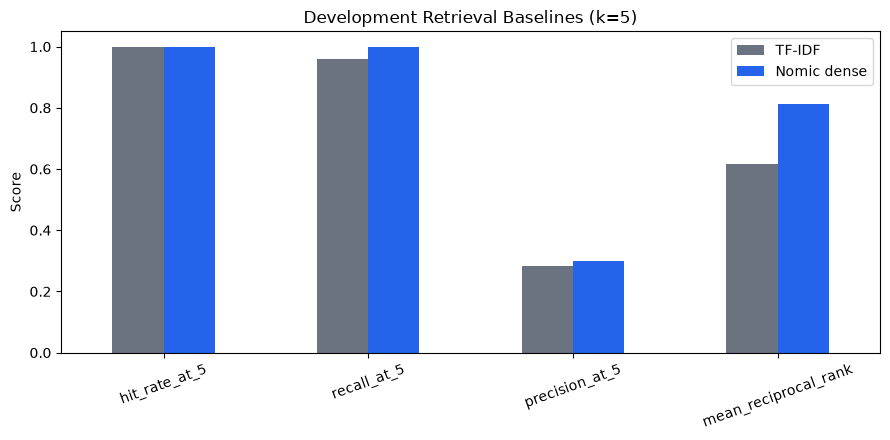

In [4]:
ax = comparison.plot.bar(figsize=(9, 4.5), color=['#6B7280', '#2563EB'])
ax.set_ylim(0, 1.05); ax.set_ylabel('Score'); ax.set_title('Development Retrieval Baselines (k=5)')
ax.tick_params(axis='x', rotation=20)
ax.figure.tight_layout()
ax.figure.savefig(ROOT / 'results' / 'figures' / 'baseline_retrieval_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

In [5]:
dense_failures = [row for row in dense_rows if row['gold_document_ids'] and not set(row['gold_document_ids']) & set(row['retrieved_document_ids'])]
{'dense_failures_at_5': len(dense_failures), 'examples': dense_failures[:3], 'test_set_accessed': dense_summary['test_set_accessed']}

{'dense_failures_at_5': 0, 'examples': [], 'test_set_accessed': False}

## Baseline interpretation

The dense retriever measures semantic similarity but does not know that a record is superseded, currently effective, approved, or authoritative. Those omissions are deliberate. They establish the improvement target for the feature-based ranker rather than silently embedding governance rules in the baseline.